# 10 — Planning and Imitation

Search for a controller while the robot moves, then copy it into a
reflex · SOC4180 Robot and AI

Hong Jeong

<figure>
<a
href="https://colab.research.google.com/github/gnoejh/soc4180/blob/main/weeks/10-planning-and-imitation/lab.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

**Before you start, two things:**

1.  **Runtime → Change runtime type → CPU is enough.** Nothing in this
    notebook renders video; the planner and the fit run on the CPU.
2.  **File → Save a copy in Drive.** This notebook is opened from GitHub
    and is *not* saved. Without a copy, your work disappears when you
    close the tab.

The setup cell downloads this week’s `lab.py` next to the notebook:
every slide’s code is that file. The planner is slower than real time on
Colab’s two cores; the notebook takes a minute or two.

## One task, two ways to solve it

**The task.** The crouched G1 is shoved sideways on the torso for 0.2 s
at t = 1 s. Holding the crouch falls at 70 N. Survive 150 N.

| weeks | how a controller is made | when the thinking happens |
|------------------------|------------------------|------------------------|
| 4–6 | **derive** it: LIPM, IK, PD, a filter | before the robot moves, by you |
| 7–9 | **learn** it from a reward | before the robot moves, by an optimiser, for hours |
| **today, part 1** | **search** for it: MPPI | *while* the robot moves, 25 times a second |
| **today, part 2** | **copy** the searcher into a reflex | before, by least squares, in milliseconds |

A planner keeps no controller at all. At every decision it asks *“what
happens next if I do this?”* for 64 different *this*, does the best for
40 ms, and asks again. It needs a model that runs forward: MuJoCo, since
week 1.

One file, `lab.py`: you edit `cost()` for part 1 and `INPUTS` for part
2. **Layer 4, Control & Planning**, then **Layer 5**, learning without a
reward.

------------------------------------------------------------------------

## Where this week sits on the map

Week 8 opened with a map of RL methods (value- or policy-based,
model-based or free, on- or off-policy, table or function). The course’s
route through it:

| week | method | what is learned | the step from the week before |
|---------|--------------------|------------------|--------------------------|
| 7 | value iteration | $V^*$, $\pi^*$ on a grid | exact, but needs $P$ and $R$ as tables |
| 7b | Q-learning, SARSA | a $Q$ table | drops $P$: learns from samples |
| 8 | policy gradient, parameter-space search | one ankle gain $\theta$ | drops the table: a policy with a parameter |
| 9 | PPO + domain randomisation | two networks (shipped) | scales $\theta$ to a network; trains in many worlds |
| **10 (this week)** | **MPPI; behaviour cloning** | **a plan every step; a copy** | **uses the simulator as a model; learns from an expert, not a reward** |
| 11 | perception and a check | — | the policy’s input becomes pixels and words |

Weeks 7–9 learned a policy **before** the robot moves. Part 1 uses
MuJoCo as a **model** and plans **while** it moves (model-based; nothing
is learned). Part 2 learns a policy again, from an **expert** instead of
a reward (imitation: not RL, but the same states, actions and policies).

------------------------------------------------------------------------

## Colour code

| symbol | meaning | colour |
|------------------------|------------------------|------------------------|
| ${\color{#3b7dd8}{x_t}}$ | the robot’s **state** at step $t$: everything physics needs (`qpos`, `qvel`, …) | <span style="color:#3b7dd8">blue</span> |
| ${\color{#e8743b}{u_t}}$, ${\color{#e8743b}{U}}$ | a **control** at step $t$; the **plan** $U = (u_0, \dots, u_{H-1})$ | <span style="color:#e8743b">orange</span> |
| ${\color{#2a9d5c}{c}}$, ${\color{#2a9d5c}{J}}$ | the **cost** of one step; the total cost of one imagined future | <span style="color:#2a9d5c">green</span> |
| ${\color{#b07d12}{\varepsilon_k}}$, ${\color{#b07d12}{\sigma}}$ | a random **change** to the plan; its standard deviation | <span style="color:#b07d12">gold</span> |
| ${\color{#8e44ad}{w_k}}$ | the **weight** given to future $k$ | <span style="color:#8e44ad">purple</span> |
| ${\color{#c0392b}{\lambda}}$ | the **temperature**: how strongly low cost wins the weight | <span style="color:#c0392b">red</span> |

$H$ is the **horizon** in plan steps, $K$ the number of sampled futures,
$f$ the simulator:
${\color{#3b7dd8}{x_{t+1}}} = f({\color{#3b7dd8}{x_t}}, {\color{#e8743b}{u_t}})$.

Part 2 adds ${\color{#3b7dd8}{\mathbf{z}}}$, the **inputs** the copy
sees, and ${\color{#2a9d5c}{a^*}}$, the **expert’s** action (green
again: the expert is what the copy is scored against).

------------------------------------------------------------------------

## Setting up

In [1]:
import importlib.util, sys, urllib.request
from pathlib import Path
try:
    on_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    on_colab = False
if on_colab:
    %pip install -q --upgrade "soc4180[rl] @ git+https://github.com/gnoejh/soc4180.git"
    urllib.request.urlretrieve("https://raw.githubusercontent.com/gnoejh/soc4180/main/weeks/10-planning-and-imitation/lab.py", "lab.py")
sys.path.insert(0, str(Path.cwd()))
import soc4180, lab

In [2]:
import inspect, os, time
import numpy as np
import matplotlib.pyplot as plt
import mujoco
from soc4180 import planning
from soc4180.estimation import gravity_body

world = lab.World()                  # the G1 + six position sensors, crouched at 0.74 m
mppi = planning.MPPI(world.model, world.ctrl0, world.acts, samples=lab.SAMPLES, horizon=lab.HORIZON,
                     sigma=lab.SIGMA, temperature=lab.TEMPERATURE, seed=0)
mppi.cost = lab.cost                 # exactly what lab.py's main() does
print(f"planned servos: {len(world.acts)} (both legs)   cores here: {os.cpu_count()}, "
      f"rollout threads: {len(mppi._datas)}")

planned servos: 12 (both legs)   cores here: 36, rollout threads: 16

`lab.World` is the G1 from `planning.planning_model()` — six position
sensors added by `MjSpec` (feet, hands, head, centre of mass), so every
imagined future records where they went.

------------------------------------------------------------------------

## `lab.World`: one robot, crouched

Everything the lab does happens to one `World`. Its first three methods,
printed from `lab.py` (the fourth, `inputs()`, is part 2’s and comes
later):

In [3]:
print("class World:")
for f in (lab.World.__init__, lab.World.reset, lab.World.tilt_deg):
    print(inspect.getsource(f))

class World:
    def __init__(self):
        self.model = planning.planning_model()
        self.data = mujoco.MjData(self.model)
        self.torso = mujoco.mj_name2id(self.model, mujoco.mjtObj.mjOBJ_BODY, "torso_link")
        self.q0, self.ctrl0 = planning.crouch(self.model)
        self.acts = planning.actuators_for(self.model)
        self.legs = self.model.actuator_trnid[self.acts, 0]
        self.qadr = self.model.jnt_qposadr[self.legs]
        self.vadr = self.model.jnt_dofadr[self.legs]

    def reset(self):
        mujoco.mj_resetData(self.model, self.data)
        self.data.qpos[:] = self.q0; self.data.qpos[2] = 0.74
        mujoco.mj_forward(self.model, self.data)

    def tilt_deg(self):
        x, y = self.data.qpos[4], self.data.qpos[5]
        return float(np.degrees(np.arccos(np.clip(1 - 2 * (x * x + y * y), -1, 1))))


------------------------------------------------------------------------

## `lab.World`, line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `planning.planning_model()` | the G1 scene plus six position sensors (feet, hands, head, CoM) | every imagined future records where they went, for `cost()` |
| `mujoco.MjData(self.model)` | the **real** robot’s state ${\color{#3b7dd8}{x}}$ | the planner is *not* in `World`: `MPPI` keeps its own `MjData` per thread, so imagining never moves this one |
| `mj_name2id(..., "torso_link")` | the torso’s body id | where `run` pushes |
| `planning.crouch(self.model)` | `q0`: week 4’s bent-knee crouch (36 `qpos`); `ctrl0`: its 29 servo targets | every controller adds to `ctrl0`; `hold` returns it unchanged |

*(continued on the next slide)*

------------------------------------------------------------------------

## `lab.World`, line by line (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `planning.actuators_for(self.model)` | `acts`: the 12 leg actuators, left leg then right, hip to ankle | `acts[4]`, `acts[10]` are the two ankle pitches |
| `actuator_trnid`, `jnt_qposadr`, `jnt_dofadr` | each leg servo’s joint, its `qpos` slot (7–18) and its `qvel` slot (6–17) | off by one: the free base spends 7 numbers on position, 6 on velocity (week 2b) |
| `reset()` | `mj_resetData`, the crouch, pelvis at **0.74 m**, `mj_forward` | at `q0`’s own 0.79 m the feet would hang 3.7 cm above the floor |
| `tilt_deg()` | $\arccos(1 - 2(x^2 + y^2))$ from the pelvis quaternion’s $x, y$ | the angle between pelvis $z$ and world $z$ — the same formula as `cost()`’s `upright`; `clip` stops rounding leaving $[-1, 1]$ |

------------------------------------------------------------------------

## MPC, written as an optimisation problem

At every decision the planner tries to solve

$$\min_{{\color{#e8743b}{u_0}},\,\dots,\,{\color{#e8743b}{u_{H-1}}}} \;\;
{\color{#2a9d5c}{J}} = \sum_{t=0}^{H-1} {\color{#2a9d5c}{c}}({\color{#3b7dd8}{x_t}}, {\color{#e8743b}{u_t}})
\qquad\text{subject to}\qquad
{\color{#3b7dd8}{x_{t+1}}} = f({\color{#3b7dd8}{x_t}}, {\color{#e8743b}{u_t}}),\quad
{\color{#3b7dd8}{x_0}} = {\color{#3b7dd8}{x_{\text{now}}}}$$

- ${\color{#e8743b}{u_0, \dots, u_{H-1}}}$ — the **unknowns**: what to
  command at each of the next $H$ steps
- ${\color{#2a9d5c}{c}}$ — how bad one step is (too low, tilted,
  rushing); **you write it**, in `cost()`
- $f$ **is** `mj_step`, contacts and all; ${\color{#3b7dd8}{x_0}}$ is
  the robot as it is right now

Week 3’s IK idea — *write what you want as a number, search for the
input that makes it small* — except that the unknown is a whole
**sequence** and the number comes from **running physics forward**. A
gradient would have to pass through 200 physics steps and every foot
contact switching on or off. **MPPI never differentiates $f$**: it only
runs it, many times, and compares.

------------------------------------------------------------------------

## Receding horizon, step by step

In [4]:
steps = mppi.H * mppi.substeps
print(f"H          = {mppi.H} knots of {mppi.knot * 1000:.0f} ms = {mppi.H * mppi.knot:.1f} s ahead "
      f"= {steps} physics steps of {world.model.opt.timestep * 1000:.0f} ms")
print(f"u_t        = {len(mppi.actuators)} leg servo targets (radians added to the crouch)")
print(f"unknowns   = {mppi.H} x {len(mppi.actuators)} = {mppi.U.size} numbers")
print(f"K          = {mppi.K} futures, sigma {mppi.sigma} rad, lambda {mppi.temperature}")
print(f"per decision: {mppi.K} x {steps} = {mppi.K * steps:,} physics steps, to choose {mppi.knot * 1000:.0f} ms of action")

H          = 10 knots of 40 ms = 0.4 s ahead = 200 physics steps of 2 ms
u_t        = 12 leg servo targets (radians added to the crouch)
unknowns   = 10 x 12 = 120 numbers
K          = 64 futures, sigma 0.15 rad, lambda 0.05
per decision: 64 x 200 = 12,800 physics steps, to choose 40 ms of action

1.  **Measure** ${\color{#3b7dd8}{x_{\text{now}}}}$ (`mj_getState`, the
    whole robot as one vector).
2.  **Solve** the problem above, approximately, starting from the old
    plan.
3.  **Apply only** ${\color{#e8743b}{u_0}}$, for one knot.
4.  **Shift**: ${\color{#e8743b}{u_1, \dots, u_{H-1}}}$ start the next
    plan; a zero is appended. Go to 1.

The plan always reaches 0.4 s ahead, and that future keeps moving — it
*recedes* like a horizon as you walk toward it.

------------------------------------------------------------------------

## MPPI: which future?

**Model-predictive path integral** control (Williams et al., 2017) turns
$K$ scored futures into one plan:

$${\color{#8e44ad}{w_k}} = \frac{\exp\!\big(-({\color{#2a9d5c}{J_k}} - {\color{#2a9d5c}{J_{\min}}})/{\color{#c0392b}{\lambda}}\big)}{\sum_j \exp\!\big(-({\color{#2a9d5c}{J_j}} - {\color{#2a9d5c}{J_{\min}}})/{\color{#c0392b}{\lambda}}\big)}, \qquad
{\color{#e8743b}{U}} \leftarrow \sum_k {\color{#8e44ad}{w_k}}\,({\color{#e8743b}{U}} + {\color{#b07d12}{\varepsilon_k}})
= {\color{#e8743b}{U}} + \sum_k {\color{#8e44ad}{w_k}}\,{\color{#b07d12}{\varepsilon_k}}$$

- ${\color{#b07d12}{\varepsilon_k}}$ — a random change,
  ${\color{#b07d12}{\sigma}}$ radians on each servo target at each knot;
  $\varepsilon_0 = 0$ keeps the old plan as a candidate
- ${\color{#2a9d5c}{J_k}}$ — the cost of future $k$, summed over its
  horizon
- ${\color{#8e44ad}{w_k}}$ — all positive, summing to 1. **Every
  ${\color{#c0392b}{\lambda}}$ of extra cost divides the weight by
  $e$**:
  ${\color{#8e44ad}{w_i}}/{\color{#8e44ad}{w_j}} = e^{-({\color{#2a9d5c}{J_i}} - {\color{#2a9d5c}{J_j}})/{\color{#c0392b}{\lambda}}}$
- ${\color{#c0392b}{\lambda}} \to 0$ keeps only the best future;
  ${\color{#c0392b}{\lambda}} \to \infty$ averages them all and ignores
  the costs

Subtracting ${\color{#2a9d5c}{J_{\min}}}$ changes no weight (it cancels
top and bottom) but stops $e^{-J/\lambda}$ underflowing to $0/0$ when
$J$ is in the tens and ${\color{#c0392b}{\lambda}} = 0.05$.

------------------------------------------------------------------------

## Where the softmin comes from

Keeping only the best of 64 trusts luck and throws 63 simulations away.
Ask instead for weights ${\color{#8e44ad}{w_k}} \ge 0$,
$\sum_k {\color{#8e44ad}{w_k}} = 1$, that minimise

$$F({\color{#8e44ad}{w}}) \;=\; \underbrace{\sum_k {\color{#8e44ad}{w_k}}\,{\color{#2a9d5c}{J_k}}}_{\text{average cost}}
\;+\; {\color{#c0392b}{\lambda}}\underbrace{\sum_k {\color{#8e44ad}{w_k}} \ln {\color{#8e44ad}{w_k}}}_{-\text{entropy: 0 if one } w_k = 1,\ -\ln K \text{ if all equal}}$$

**Set the derivative to zero**, with a Lagrange multiplier $\mu$ for the
sum:

$${\color{#2a9d5c}{J_k}} + {\color{#c0392b}{\lambda}}\,(\ln {\color{#8e44ad}{w_k}} + 1) + \mu = 0
\;\;\Longrightarrow\;\;
{\color{#8e44ad}{w_k}} = C\,e^{-{\color{#2a9d5c}{J_k}}/{\color{#c0392b}{\lambda}}},
\qquad C = 1 \big/ \textstyle\sum_j e^{-{\color{#2a9d5c}{J_j}}/{\color{#c0392b}{\lambda}}}$$

${\color{#c0392b}{\lambda}}$ prices *spreading the bet*: low cost pulls
the weight onto the best futures, the entropy term pulls it back towards
all of them. How many futures really vote is the **effective sample
size**

$$K_{\text{eff}} = 1 \Big/ \textstyle\sum_k {\color{#8e44ad}{w_k}}^2 \qquad (1 \text{ if one weight is } 1,\; K \text{ if all are } 1/K).$$

------------------------------------------------------------------------

## One MPPI update in one dimension

A **made-up** cost of one number $u$: a shallow valley on the left, a
deeper one near $u = 1.2$. Plan ${\color{#e8743b}{U}} = 0.4$; twelve
changes, ${\color{#b07d12}{\sigma}} = 0.5$, the first kept at 0;
${\color{#c0392b}{\lambda}} = 0.1$.

In [5]:
def J1(u):
    return 0.5 * (u ** 2 - 1.2) ** 2 - 0.35 * u + 0.6         # made up: two valleys

rng = np.random.default_rng(26)
U_old, sig, lam = 0.4, 0.5, 0.1
eps = rng.normal(0, sig, 12); eps[0] = 0.0                     # sample; keep the old plan
u_s = U_old + eps; J_s = J1(u_s)                               # "simulate" and score
w_s = np.exp(-(J_s - J_s.min()) / lam); w_s /= w_s.sum()       # softmin weights
U_new = w_s @ u_s                                              # the weighted mean
print(f"best sample {u_s[np.argmin(J_s)]:+.3f}   plain mean {u_s.mean():+.3f}   "
      f"weighted mean {U_new:+.3f}   K_eff {1 / np.sum(w_s ** 2):.1f} of 12")

best sample +1.181   plain mean +0.535   weighted mean +1.083   K_eff 4.1 of 12

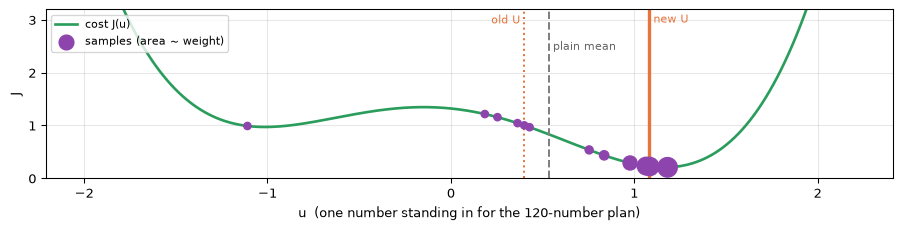

In [6]:
uu = np.linspace(-2.0, 2.2, 400)
fig, ax = plt.subplots(figsize=(9.5, 2.5))
ax.plot(uu, J1(uu), color="#2a9d5c", lw=2, label="cost J(u)")
ax.scatter(u_s, J_s, s=30 + 600 * w_s, color="#8e44ad", zorder=3, label="samples (area ~ weight)")
ax.axvline(U_old, color="#e8743b", ls=":", lw=1.5); ax.text(U_old, 3.1, "old U ", color="#e8743b", fontsize=8, va="top", ha="right")
ax.axvline(u_s.mean(), color="0.5", ls="--", lw=1.5); ax.text(u_s.mean(), 2.6, " plain mean", color="0.4", fontsize=8, va="top")
ax.axvline(U_new, color="#e8743b", lw=2.5); ax.text(U_new, 3.1, " new U", color="#e8743b", fontsize=8, va="top")
ax.set_ylim(0, 3.2); ax.set_xlabel("u  (one number standing in for the 120-number plan)"); ax.set_ylabel("J")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left"); fig.tight_layout(); plt.show()

Nothing needed $dJ/du$: the planner only *evaluated* $J$ at twelve
points, which is all a simulator can do for us. On the robot $u$ is 120
numbers and each evaluation is 200 physics steps; the update is exactly
this.

------------------------------------------------------------------------

## The whole planner

`soc4180.planning.MPPI.plan`, printed from the package:

In [7]:
src = inspect.getsource(planning.MPPI.plan)
print(src[src.index("        mujoco.mj_getState"):])

        mujoco.mj_getState(self.model, data, self._state, self._spec)          # 1. where we are
        eps = self.rng.normal(0.0, self.sigma, (self.K, self.H, len(self.actuators)))
        eps[0] = 0.0                                                            # keep the old plan as a candidate
        U = self.U[None] + eps                                                  # 2. K perturbed plans
        ctrl = np.tile(self.nominal_ctrl, (self.K, self.H, 1))
        ctrl[:, :, self.actuators] += U
        ctrl = np.repeat(ctrl, self.substeps, axis=1)                           #    each knot held for its substeps
        states, sens = _rollout.rollout(self.model, self._datas,                 # 3. K futures, in parallel
                                        np.tile(self._state, (self.K, 1)), ctrl,
                                        persistent_pool=True)
        costs = np.asarray(self.cost(Rollouts(self.model, states, sens, self._adr)), float)   # 4. score
        w = np.exp(-(c

Steps 1–7 are the numbered comments. `rollout.rollout` steps the 64
copies in C on a thread pool, one `MjData` per thread; `xfrc_applied` is
not part of the state, so **the planner never sees the shove coming** —
it only sees what the shove has already done.

------------------------------------------------------------------------

## `MPPI.plan`, line by line 1: sample and imagine

| code | the maths | why |
|------------------------|------------------------|------------------------|
| `mj_getState(..., self._state, self._spec)` | ${\color{#3b7dd8}{x_0}} = {\color{#3b7dd8}{x_{\text{now}}}}$ | `FULLPHYSICS`: time, `qpos`, `qvel` and the rest physics needs, as one vector every future starts from |
| `eps = self.rng.normal(0.0, self.sigma, (self.K, self.H, len(self.actuators)))` | ${\color{#b07d12}{\varepsilon_k}}$, $K \times H \times 12$ numbers of s.d. ${\color{#b07d12}{\sigma}}$ | one random change per future, per knot, per leg servo |
| `eps[0] = 0.0` | ${\color{#b07d12}{\varepsilon_0}} = 0$ | the old plan stays a candidate, so a good plan is never lost to bad luck |
| `U = self.U[None] + eps` | ${\color{#e8743b}{U}} + {\color{#b07d12}{\varepsilon_k}}$ | $K$ perturbed plans, in radians added to the crouch |

*(continued on the next slide)*

------------------------------------------------------------------------

## `MPPI.plan`, line by line 1: sample and imagine (cont.)

| code | the maths | why |
|------------------------|------------------------|------------------------|
| `ctrl = np.tile(self.nominal_ctrl, ...)`; `ctrl[:, :, self.actuators] += U` | ${\color{#e8743b}{u_t}}$ for all 29 servos | the 17 servos outside the legs keep the crouch |
| `np.repeat(ctrl, self.substeps, axis=1)` | each knot held for `substeps` physics steps | a plan step is 40 ms, a physics step 2 ms |
| `_rollout.rollout(self.model, self._datas, np.tile(self._state, (self.K, 1)), ctrl, ...)` | ${\color{#3b7dd8}{x_{t+1}}} = f({\color{#3b7dd8}{x_t}}, {\color{#e8743b}{u_t}})$, $K$ times | `mj_step` in C on a thread pool; returns every state and every sensor reading of every future |

------------------------------------------------------------------------

## `MPPI.plan`, line by line 2: score, weight, shift

| code | the maths | why |
|------------------------|------------------------|------------------------|
| `costs = self.cost(Rollouts(self.model, states, sens, self._adr))` | ${\color{#2a9d5c}{J_k}} = \sum_t {\color{#2a9d5c}{c}}({\color{#3b7dd8}{x_t}})$ | `Rollouts` names the arrays (`pelvis_height`, `com`, `foot`, …); **your** `cost()` returns one number per future |
| `w = np.exp(-(costs - costs.min()) / self.temperature)` | $e^{-({\color{#2a9d5c}{J_k}} - {\color{#2a9d5c}{J_{\min}}})/{\color{#c0392b}{\lambda}}}$ | the softmin; subtracting $J_{\min}$ stops underflow to $0/0$ |
| `w /= w.sum()` | ${\color{#8e44ad}{w_k}}$, summing to 1 | a weighted average needs weights that sum to 1 |
| `self.U = np.einsum("k,khn->hn", w, U)` | ${\color{#e8743b}{U}} \leftarrow \sum_k {\color{#8e44ad}{w_k}}\,({\color{#e8743b}{U}} + {\color{#b07d12}{\varepsilon_k}})$ | sum over futures $k$, for every knot $h$ and servo $n$ |

*(continued on the next slide)*

------------------------------------------------------------------------

## `MPPI.plan`, line by line 2: score, weight, shift (cont.)

| code | the maths | why |
|------------------------|------------------------|------------------------|
| `u0 = self.U[0].copy()` | ${\color{#e8743b}{u_0}}$ | only the first knot is executed |
| `np.roll(self.U, -1, axis=0); self.U[-1] = 0.0` | ${\color{#e8743b}{u_1, \dots, u_{H-1}}}, 0$ | the shift: the rest of this plan seeds the next decision |
| `self.last_costs = costs` | the 64 ${\color{#2a9d5c}{J_k}}$ | kept so the temperature slide can re-weight them |
| `out = self.nominal_ctrl.copy(); out[self.actuators] += u0` | crouch $+\ {\color{#e8743b}{u_0}}$ | returns all 29 servo targets, ready for `data.ctrl` |

`self.U` is the planner’s **memory**: that is why every run starts with
`mppi.reset()`.

------------------------------------------------------------------------

## The cost *is* the specification

In [8]:
print(inspect.getsource(lab.cost))

def cost(r):
    mid = 0.5 * (r.foot("left") + r.foot("right"))                     # between the feet
    c = (10.0 * (r.pelvis_height - 0.72) ** 2                           # stay tall
         + 5.0 * (1.0 - r.upright)                                      # stay upright
         + 20.0 * np.sum((r.com[..., :2] - mid[..., :2]) ** 2, -1)      # mass over the feet
         + 0.01 * np.sum(r.qvel[..., :6] ** 2, -1)                      # "still": pelvis speed
         + 100.0 * (r.pelvis_height < 0.5))                             # fallen
    return c.sum(axis=1)


Every accessor is $K \times T$ — one row per future, one column per
physics step; `c.sum(axis=1)` gives one ${\color{#2a9d5c}{J_k}}$ per
future. Five lines say what *balance* means: stay tall, stay upright,
keep the centre of mass between the feet, do not rush, do not be on the
floor. **Nothing says how**: not “use the ankles”, not “step”.

And **nothing says “stop”** or “stay where you started”. Keep that in
mind for two slides. It is the week-8 reward turned upside down and
evaluated on the future instead of the past.

------------------------------------------------------------------------

## What `r` holds

`r` is a `planning.Rollouts`: the 64 imagined futures, each 200 physics
steps long. Every field is an array with **one row per future, one
column per step**:

| field | shape | what it is |
|------------------------|------------------------|------------------------|
| `r.pelvis_height` | $K \times T$ | `qpos[2]`: the pelvis height, metres |
| `r.upright` | $K \times T$ | $1 - 2(x^2 + y^2)$ from the pelvis quaternion: the cosine of the tilt, 1 upright, 0 lying down |
| `r.foot("left")`, `r.foot("right")` | $K \times T \times 3$ | the foot sites’ world position, from the sensors `planning_model()` added |
| `r.com` | $K \times T \times 3$ | the whole robot’s centre of mass (`SUBTREECOM` of the pelvis) |
| `r.qvel[..., :6]` | $K \times T \times 6$ | the free base’s velocities: pelvis linear (3) and angular (3) |

`[..., :2]` keeps $x, y$ (the floor plane); `np.sum(..., -1)` adds over
those last-axis components. Also there, unused here: `r.hand(side)`,
`r.head`, `r.yaw`.

------------------------------------------------------------------------

## What each term pays for

| term | it costs … | so the search prefers futures that … |
|------------------------|------------------------|------------------------|
| `10.0 * (r.pelvis_height - 0.72) ** 2` | the squared distance from a 0.72 m pelvis | stay at crouch height, neither sinking nor straightening |
| `5.0 * (1.0 - r.upright)` | 0 upright, growing with the tilt | keep the pelvis level |
| `20.0 * np.sum((r.com[..., :2] - mid[..., :2]) ** 2, -1)` | how far the CoM sits, in the floor plane, from `mid`, the point between the feet | keep the mass over the feet — or **move the feet under the mass** |
| `0.01 * np.sum(r.qvel[..., :6] ** 2, -1)` | the pelvis speed, squared (“still”) | do not rush; the smallest weight |
| `100.0 * (r.pelvis_height < 0.5)` | 100 per step with the pelvis below 0.5 m | are not on the floor; the same 0.5 m `run` calls a fall |
| `c.sum(axis=1)` | adds over the $T$ steps | one ${\color{#2a9d5c}{J_k}}$ per future, as `plan` expects |

The weights set the exchange rate between the terms. No term mentions
the feet’s *starting* place, which is why the robot is free to walk
away.

------------------------------------------------------------------------

## `lab.run`: one shove

Every experiment in the lab, part 1 and part 2, is a call to this
function with a different `decide`:

In [9]:
print(inspect.getsource(lab.run))

def run(world, push, decide, seconds=4.0, *, record=False):
    """One shove. decide(world) -> full ctrl, called every knot. Returns (stood, info)."""
    world.reset()
    d, frames, X, Y, zmin = world.data, [], [], [], 9.0
    feet = [mujoco.mj_name2id(world.model, mujoco.mjtObj.mjOBJ_SITE, f"{s}_foot") for s in ("left", "right")]
    start = [d.site_xpos[f][:2].copy() for f in feet]
    substeps = int(round(0.04 / world.model.opt.timestep))
    while d.time < seconds - 1e-9:
        x = world.inputs()
        ctrl = decide(world)
        X.append(x); Y.append(ctrl[world.acts] - world.ctrl0[world.acts])
        for _ in range(substeps):
            d.xfrc_applied[world.torso, 1] = push if 1.0 <= d.time < 1.2 else 0.0
            d.ctrl[:] = ctrl
            mujoco.mj_step(world.model, d)
            if record and int(round(d.time / world.model.opt.timestep)) % 10 == 0:
                frames.append(d.qpos.copy())
        zmin = min(zmin, d.qpos[2])
    stood = zmin > 0.5 and world.ti

------------------------------------------------------------------------

## `lab.run`, line by line 1: the decisions

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `world.reset()` | the crouch, pelvis at 0.74 m, time 0 | every controller meets the same robot and the same shove |
| `start = [d.site_xpos[f][:2].copy() for f in feet]` | the two feet’s $x, y$ at the start | to measure how far they travel |
| `substeps = int(round(0.04 / world.model.opt.timestep))` | physics steps per decision | one decision per 40 ms knot, 25 a second, like MPPI’s |
| `while d.time < seconds - 1e-9:` | 4 s, i.e. 100 decisions | the `1e-9` stops rounding in the summed time adding a 101st |
| `x = world.inputs()` | what a copy would see, ${\color{#3b7dd8}{\mathbf z_i}}$ | read **before** the decision, so it is what the decision was made from |
| `ctrl = decide(world)` | the controller: 29 servo targets | `hold`, `plan`, `ankle` or `copy` — `run` never knows which |
| `Y.append(ctrl[world.acts] - world.ctrl0[world.acts])` | the action ${\color{#2a9d5c}{a_i^*}}$: 12 leg targets minus the crouch | with `X.append(x)`, one training pair for part 2 |

------------------------------------------------------------------------

## `lab.run`, line by line 2: the shove and the verdict

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `for _ in range(substeps):` | holds `ctrl` for one knot of physics | the controller decides 25 times a second, physics runs at 500 Hz |
| `d.xfrc_applied[world.torso, 1] = push if 1.0 <= d.time < 1.2 else 0.0` | a force on `torso_link`: row = body, column 1 = world $y$, sideways; for 0.2 s at t = 1 s | `xfrc_applied` is not state, so the planner’s copied futures never contain it |
| `d.ctrl[:] = ctrl; mujoco.mj_step(world.model, d)` | the real world moves one step |  |
| `if record and ... % 10 == 0: frames.append(d.qpos.copy())` | `qpos` every 10 physics steps | for the plot and the viewer replay; only when asked |

*(continued on the next slide)*

------------------------------------------------------------------------

## `lab.run`, line by line 2: the shove and the verdict (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `zmin = min(zmin, d.qpos[2])` | the lowest pelvis height, checked once per decision | a fall is “ever down”, not “down at the end” |
| `stood = zmin > 0.5 and world.tilt_deg() < 15.0` | **fell** = pelvis ever below 0.5 m, or still tilted over 15° at 4 s | catches a slow fall that has not reached the floor |
| `moved = sum(... np.linalg.norm(d.site_xpos[f][:2] - s) ...)` | both feet’s straight-line distance from where they started, added | MPPI’s 3.04 m |
| `return stood, dict(moved=..., X=..., Y=..., frames=...)` | the verdict, plus `X` (100 × inputs) and `Y` (100 × 12) | part 2 fits on `X`, `Y` |

------------------------------------------------------------------------

## Shove it: 150 N

`lab.run(world, push, decide)` is the lab’s whole experiment: reset,
call `decide` every 40 ms, shove at t = 1.0–1.2 s, and count a fall as a
pelvis below 0.5 m or a final tilt over 15°.

In [10]:
hold = lambda w: w.ctrl0                          # do nothing: hold the crouch
cost_log = []
def plan(w):                                      # the planner, logging its 64 costs
    ctrl = mppi.plan(w.data); cost_log.append((w.data.time, mppi.last_costs.copy()))
    return ctrl

for name, decide in (("hold", hold), ("MPPI", plan)):
    mppi.reset(); t0 = time.time()
    stood, info = lab.run(world, 150.0, decide, record=(name == "MPPI"))
    ms = 1000 * (time.time() - t0) / len(info["X"])
    print(f"{name:5s} 150 N: {'stood' if stood else 'FELL ':5s}  feet moved {info['moved']:.2f} m"
          + (f"   {ms:.0f} ms per decision" if name == "MPPI" else ""))
planned = info

hold  150 N: FELL   feet moved 0.94 m
MPPI  150 N: stood  feet moved 3.04 m   86 ms per decision

Measured with `lab.py` on the course machine: hold falls; MPPI stands,
feet moved **3.04 m**, **81–98 ms** per decision on 16 threads. Your
laptop differs in milliseconds, not in who falls.

------------------------------------------------------------------------

## How: it steps, and never stops

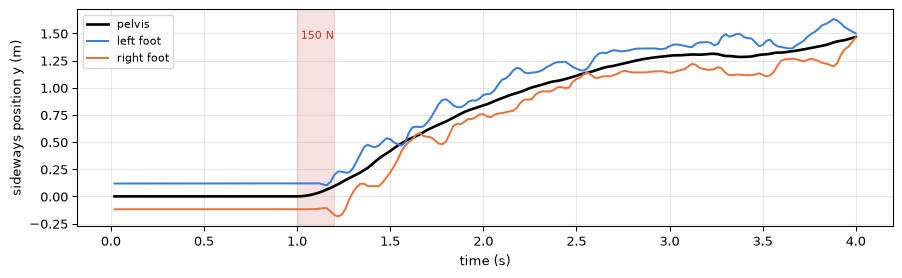

In [11]:
d_draw = mujoco.MjData(world.model)
feet = [mujoco.mj_name2id(world.model, mujoco.mjtObj.mjOBJ_SITE, f"{s}_foot") for s in ("left", "right")]
rows = []
for q in planned["frames"]:
    d_draw.qpos[:] = q; mujoco.mj_kinematics(world.model, d_draw)
    rows.append((q[1], d_draw.site_xpos[feet[0]][1], d_draw.site_xpos[feet[1]][1]))
rows = np.array(rows); tt = np.arange(1, len(rows) + 1) * 10 * world.model.opt.timestep
fig, ax = plt.subplots(figsize=(9.5, 3.0))
ax.plot(tt, rows[:, 0], color="k", lw=2, label="pelvis")
ax.plot(tt, rows[:, 1], color="#3b7dd8", lw=1.5, label="left foot")
ax.plot(tt, rows[:, 2], color="#e8743b", lw=1.5, label="right foot")
ax.axvspan(1.0, 1.2, color="#c0392b", alpha=0.15)
ax.text(1.02, rows.min() + 0.9 * (rows.max() - rows.min()), "150 N", fontsize=8, color="#c0392b")
ax.set_xlabel("time (s)"); ax.set_ylabel("sideways position y (m)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

After the shove the feet chase the pelvis: one lifts and lands further
along, then the other. **The planner discovered stepping**, because
among 64 random futures some happened to put a foot out, and those did
not end on the floor.

And it never stops: nothing in `cost()` rewards staying put, so the
robot walks sideways. That is the cost doing exactly what it says (Try 2
adds the missing term).

------------------------------------------------------------------------

## Temperature: how many futures vote?

The 100 decisions of that run, each with its 64 costs, re-weighted at
four temperatures:

In [12]:
def k_eff(J, lam):
    w = np.exp(-(J - J.min()) / lam); w /= w.sum()
    return 1 / np.sum(w ** 2)

for label, sel in (("before the shove", [c for t, c in cost_log if t < 1.0]),
                   ("shove and after ", [c for t, c in cost_log if t >= 1.0])):
    gap = np.median([np.sort(c)[1] - np.sort(c)[0] for c in sel])
    row = "  ".join(f"lam {l:<5}: {np.median([k_eff(c, l) for c in sel]):4.1f}" for l in (0.005, 0.05, 0.5, 5.0))
    print(f"{label}: runner-up behind the best by {gap:4.1f} (median)\n    K_eff of 64 -> {row}")

before the shove: runner-up behind the best by  8.9 (median)
    K_eff of 64 -> lam 0.005:  1.0  lam 0.05 :  1.0  lam 0.5  :  1.0  lam 5.0  :  4.7
shove and after : runner-up behind the best by  3.8 (median)
    K_eff of 64 -> lam 0.005:  1.0  lam 0.05 :  1.0  lam 0.5  :  1.0  lam 5.0  :  6.4

Read the gap in units of ${\color{#c0392b}{\lambda}}$: at the lab’s
${\color{#c0392b}{\lambda}} = 0.05$ the runner-up is 3.8–8.9 behind,
i.e. 76–178 temperatures, so its weight is
$e^{-\text{gap}/0.05} \approx 0$. **One future is in charge**: on this
robot, with this cost, MPPI is in practice *keep the best of 64*, and
averaging begins only near ${\color{#c0392b}{\lambda}} = 5$. Not a bug —
it stands — but the 1-D picture’s gentle averaging is not what happens
here. Remember it for part 2: what the planner does is whichever random
sample won.

------------------------------------------------------------------------

## The price of thinking

| controller           | per decision            | what it costs              |
|------------------------|------------------------|------------------------|
| hold the crouch      | 0                       | nothing, and falls at 70 N |
| week 8’s ankle rule  | ~1 µs                   | two multiplications        |
| **MPPI, 64 × 0.4 s** | **81–98 ms** (measured) | **12,800 physics steps**   |

A decision covers 40 ms of robot time, so ~90 ms of planning is about
**0.4× real time** on 16 threads: the planner is *slower* than the robot
it drives, and slower still on a laptop with fewer cores. Real planners
(MuJoCo MPC, Atlas) use a simpler model, fewer samples, or a GPU.

How much search is enough was measured earlier on the same robot
(CLAUDE.md, week 11 of the old course): 2 samples fall at 150 N; 4 and
16 stand at 150 and fall at 300; 16 with σ 0.25 stand at 300. **More
samples find rarer good futures, and width trades against count.**

**Part 2 is the other answer to this slide**: copy the slow planner into
a fast reflex.

------------------------------------------------------------------------

## Part 2: copy the expert into a reflex

Record an **expert** while it recovers from shoves of −150, −100, +100
and +150 N (`TRAIN_PUSHES`), 100 decisions each. At every decision keep
what the copy will be allowed to see, ${\color{#3b7dd8}{\mathbf z_i}}$,
and what the expert did, ${\color{#2a9d5c}{a_i^*}}$ (12 servo targets
minus the crouch):

| `INPUTS` | numbers | what they are                                           |
|----------|---------|---------------------------------------------------------|
| `tilt`   | 2       | gravity in the pelvis frame, x and y                    |
| `spin`   | 3       | pelvis angular velocity                                 |
| `legs`   | 12      | leg angles minus the crouch                             |
| `speeds` | 12      | leg angular velocities                                  |
| `time`   | 1       | seconds since the start — the planner never looks at it |

The copy is **linear**:
${\color{#e8743b}{a}} = W {\color{#3b7dd8}{\mathbf z}} + b$. One matrix
product: microseconds instead of 90 ms. Two experts:

- `EXPERT = "planner"` — part 1’s MPPI;
- `EXPERT = "ankle"` — week 8’s rule: both ankle pitches
  $+= 0.3\,\mathrm{clip}(2 g_x, -1, 1)$, where $g_x$ is the forward
  tilt.

------------------------------------------------------------------------

## `World.inputs`: what the copy may see

In [13]:
print(inspect.getsource(lab.World.inputs))

    def inputs(self):
        d = self.data
        parts = {
            "tilt": gravity_body(d)[:2],
            "spin": d.qvel[3:6],
            "legs": d.qpos[self.qadr] - self.q0[self.qadr],
            "speeds": d.qvel[self.vadr],
            "time": [d.time],
        }
        return np.concatenate([np.asarray(parts[k], float) for k in INPUTS])


`d` is the real robot’s `MjData`; `INPUTS` is the list at the top of
`lab.py`.

------------------------------------------------------------------------

## `World.inputs`, line by line

| code | numbers | what it is |
|------------------------|------------------------|------------------------|
| `gravity_body(d)[:2]` | 2 | **tilt**: the unit gravity vector turned into the pelvis frame, its $x$ (forward) and $y$ (sideways) parts; both 0 when upright |
| `d.qvel[3:6]` | 3 | **spin**: the free base’s angular velocity, rad/s (`qvel[0:3]` is its linear velocity) |
| `d.qpos[self.qadr] - self.q0[self.qadr]` | 12 | **legs**: each leg joint’s angle minus the crouch’s |
| `d.qvel[self.vadr]` | 12 | **speeds**: each leg joint’s angular velocity |
| `[d.time]` | 1 | **time**: seconds since the reset |
| `np.concatenate([... for k in INPUTS])` | 2 + 3 + 12 + 12 = **29** | only the parts named in `INPUTS`, in that order |

All five parts are computed every call; `INPUTS` picks which reach the
copy.

------------------------------------------------------------------------

## Recording: the expert’s decisions become data

In [14]:
import ast, textwrap                     # helpers: print slices of lab.main()
main_src = textwrap.dedent(inspect.getsource(lab.main))
main_lines = main_src.splitlines()
def between(first, last):
    """lab.main's lines from the first containing `first` to the next containing `last`."""
    i = next(n for n, l in enumerate(main_lines) if first in l)
    j = next(n for n in range(i, len(main_lines)) if last in main_lines[n])
    return textwrap.dedent("\n".join(main_lines[i:j + 1]))
def inner(name):
    """The function `name` defined inside lab.main(), exactly as written."""
    n = next(n for n in ast.walk(ast.parse(main_src)) if isinstance(n, ast.FunctionDef) and n.name == name)
    return textwrap.dedent("\n".join(main_lines[n.lineno - 1:n.end_lineno]))

In [15]:
print(between("X, Y = [], []", "scale = np.sqrt"))      # from lab.py's main()

X, Y = [], []
for p in TRAIN_PUSHES:
    mppi.reset()
    _, rec = run(world, p, expert)
    X.append(rec["X"]); Y.append(rec["Y"])
X, Y = np.vstack(X), np.vstack(Y)
reflex = fit(X, Y)
err = np.sqrt(np.mean((np.array([reflex(x) for x in X]) - Y) ** 2))
scale = np.sqrt(np.mean(Y ** 2))

`expert` is `plan` or `ankle` (shown after `fit`); `run` is the function
from part 1.

------------------------------------------------------------------------

## Recording, line by line

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `for p in TRAIN_PUSHES:` | −150, −100, +100, +150 N | both directions, so the data sees both signs of tilt |
| `mppi.reset()` | empties the planner’s stored plan | each recording starts fresh (the ankle rule has no memory to empty) |
| `_, rec = run(world, p, expert)` | one shove, 100 decisions; stood or fell is ignored | the falls are recorded too |
| `np.vstack(X), np.vstack(Y)` | 400 rows: $X$ is 400 × inputs, ${\color{#2a9d5c}{Y}}$ 400 × 12 | row $i$ is the pair $({\color{#3b7dd8}{\mathbf z_i}}, {\color{#2a9d5c}{a_i^*}})$ |
| `err = ...`; `scale = np.sqrt(np.mean(Y ** 2))` | the fit’s RMS error on the recordings; the expert’s spread | `scale` is the error of a copy that always says 0, i.e. holds the crouch |

------------------------------------------------------------------------

## Least squares, written out

Standardise each input with its mean $\mu_j$ and a **floored** spread,
$s_j = \max(\mathrm{sd}_j,\ 0.01)$, append a 1 for the bias, and stack
the $N$ decisions as rows of $Z$; the expert’s actions are the rows of
${\color{#2a9d5c}{Y}}$:

$$\min_{\Theta}\ \lVert Z\Theta - {\color{#2a9d5c}{Y}}\rVert^2 + \rho\,\lVert W\rVert^2
\;\;\Longrightarrow\;\;
(Z^\top Z + \rho I')\,\Theta = Z^\top {\color{#2a9d5c}{Y}},
\qquad \Theta = \begin{bmatrix} W \\ b \end{bmatrix}$$

$I'$ is the identity with its last (bias) entry zeroed,
$\rho = 10^{-3}$: a little ridge on the weights, none on the bias.

In [16]:
print(inspect.getsource(lab.fit))

def fit(X, Y, ridge=1e-3):
    """Least squares with a little ridge: W, b minimising |X W + b - Y|^2 + ridge |W|^2."""
    mu, sd = X.mean(0), np.maximum(X.std(0), 0.01)      # a floor: an input that never moved must not explode
    Z = np.hstack([(X - mu) / sd, np.ones((len(X), 1))])
    A = Z.T @ Z + ridge * np.eye(Z.shape[1]); A[-1, -1] -= ridge
    Wb = np.linalg.solve(A, Z.T @ Y)
    return lambda x: np.hstack([(x - mu) / sd, 1.0]) @ Wb


The floor matters: an input that never moved in the recordings has
$\mathrm{sd} \approx 0$, and dividing by it would turn any later change
into a huge number. Fit error = $\sqrt{\text{mean}(Z\Theta - Y)^2}$ on
the recordings, compared with the expert’s own spread
$\sqrt{\text{mean}\,Y^2}$.

------------------------------------------------------------------------

## `fit`, line by line

| code | the maths | why |
|------------------------|------------------------|------------------------|
| `mu, sd = X.mean(0), np.maximum(X.std(0), 0.01)` | $\mu_j$; $s_j = \max(\mathrm{sd}_j, 0.01)$, per input column | **the floor**: an input that never moved has $\mathrm{sd} \approx 0$; dividing by it would turn any later change into a huge number |
| `(X - mu) / sd` | standardised inputs | tilt (≤ 1) and speeds (rad/s) on one scale, so one ridge treats them alike |
| `np.hstack([..., np.ones((len(X), 1))])` | $Z$, with a column of 1s | the 1s’ weight is the bias $b$ |
| `A = Z.T @ Z + ridge * np.eye(Z.shape[1])` | $Z^\top Z + \rho I$, $\rho = 10^{-3}$ | the ridge keeps $A$ invertible when inputs move together |

*(continued on the next slide)*

------------------------------------------------------------------------

## `fit`, line by line (cont.)

| code | the maths | why |
|------------------------|------------------------|------------------------|
| `A[-1, -1] -= ridge` | $I \to I'$ | no ridge on the bias |
| `Wb = np.linalg.solve(A, Z.T @ Y)` | $(Z^\top Z + \rho I')\,\Theta = Z^\top {\color{#2a9d5c}{Y}}$ | the normal equations, solved once for all 12 servos: ${\color{#2a9d5c}{Y}}$ has 12 columns, so $\Theta$ is (inputs + 1) × 12 |
| `lambda x: np.hstack([(x - mu) / sd, 1.0]) @ Wb` | ${\color{#e8743b}{a}} = W {\color{#3b7dd8}{\mathbf z}} + b$ | the **reflex**: the recordings’ $\mu$, $s$ applied to a new input, then one product |

A floored input can still get a large weight: the floor stops division
by zero, not trust in an input the data never moved. The 29-input copy
shows it.

------------------------------------------------------------------------

## Three experts, one interface

Every controller in the lab is a function `decide(world)` returning 29
servo targets. Printed from `lab.py`’s `main()`:

In [17]:
for part in (between("hold = lambda", "hold = lambda"), inner("plan"), inner("ankle"),
             between("expert = {", "expert = {"), inner("copy")):
    print(part + "\n")

hold = lambda w: w.ctrl0

def plan(w):
    return mppi.plan(w.data)

def ankle(w):                                     # week 8: ankle pitch = 2 x forward tilt
    ctrl = w.ctrl0.copy()
    ctrl[w.acts[[4, 10]]] += 0.3 * np.clip(2.0 * gravity_body(w.data)[0], -1, 1)
    return ctrl

expert = {"planner": plan, "ankle": ankle}[EXPERT]

def copy(w):
    ctrl = w.ctrl0.copy()
    ctrl[w.acts] += np.clip(reflex(w.inputs()), -0.5, 0.5)
    return ctrl


------------------------------------------------------------------------

## Three experts, line by line

| decider | what it reads | what it does | cost per decision |
|------------------|------------------|------------------|------------------|
| `hold` | nothing | returns `w.ctrl0`, the crouch | 0; falls at 70 N |
| `plan` | `w.data`: the **whole** state, through `mj_getState` | `mppi.plan`: 64 futures, softmin, shift. **Random** (its samples) and with **memory** (`self.U`) | 81–98 ms |

*(continued on the next slide)*

------------------------------------------------------------------------

## Three experts, line by line (cont.)

| decider | what it reads | what it does | cost per decision |
|------------------|------------------|------------------|------------------|
| `ankle` | one number: `gravity_body(w.data)[0]`, the forward tilt $g_x$ | adds $0.3\,\mathrm{clip}(2 g_x, -1, 1)$ to `w.acts[[4, 10]]`, the two ankle pitches: at most ±0.3 rad | two multiplications |
| `copy` | `w.inputs()`: only what `INPUTS` names | crouch + `reflex(...)`, each of the 12 clipped to ±0.5 rad | one matrix product |

- `expert = {"planner": plan, "ankle": ankle}[EXPERT]` picks the one to
  record.
- `run` calls all four the same way: so the copy can be **tested exactly
  where the expert was**, and nothing in `run` changes.
- `np.clip(..., -0.5, 0.5)` is a rail: a line extrapolates without
  limit, a servo target should not.
- Only `ankle` is a function of what a 2-input copy sees; `plan` is not
  a function of *any* input list. Part 2’s table is that sentence,
  measured.

------------------------------------------------------------------------

## Copying the ankle rule, live

The ankle rule is cheap, so this cell records, fits and tests both input
sets (the same steps as `lab.py`’s `main()`, a few seconds):

In [18]:
def ankle(w):                                     # copied from lab.py's main()
    ctrl = w.ctrl0.copy()
    ctrl[w.acts[[4, 10]]] += 0.3 * np.clip(2.0 * gravity_body(w.data)[0], -1, 1)
    return ctrl

recorded = {}
for inputs in (["tilt", "spin", "legs", "speeds"], ["tilt"]):
    lab.INPUTS = inputs                           # World.inputs() reads this list
    X, Y = zip(*[(r["X"], r["Y"]) for r in (lab.run(world, p, ankle)[1] for p in lab.TRAIN_PUSHES)])
    X, Y = np.vstack(X), np.vstack(Y)
    reflex = lab.fit(X, Y); recorded[X.shape[1]] = (X, Y, reflex)
    err = np.sqrt(np.mean((np.array([reflex(x) for x in X]) - Y) ** 2))
    def copy(w):                                  # as in lab.py's main()
        ctrl = w.ctrl0.copy(); ctrl[w.acts] += np.clip(reflex(w.inputs()), -0.5, 0.5); return ctrl
    cells = "  ".join(f"{p:3.0f} N {'stood' if lab.run(world, p, copy)[0] else 'FELL '}" for p in (60, 75, 100, 150))
    print(f"{X.shape[1]:2d} inputs: fit {err:.4f} of {np.sqrt(np.mean(Y ** 2)):.4f} rad   copy: {cells}")
lab.INPUTS = ["tilt", "spin", "legs", "speeds"]
print(f"{'the expert itself:':44s}" + "  ".join(f"{p:3.0f} N {'stood' if lab.run(world, p, ankle)[0] else 'FELL '}" for p in (60, 75, 100, 150)))

29 inputs: fit 0.0032 of 0.0816 rad   copy:  60 N FELL    75 N FELL   100 N FELL   150 N FELL 
 2 inputs: fit 0.0107 of 0.0816 rad   copy:  60 N stood   75 N stood  100 N FELL   150 N FELL 
the expert itself:                           60 N stood   75 N stood  100 N FELL   150 N FELL 

The 29-input copy fits the rule **better than** the 2-input one — and
falls at every push.

------------------------------------------------------------------------

## The copy table, measured with `lab.py`

400 decisions recorded on 4 shoves; who stands (the lab.py docstring):

| expert  | inputs                     | fit error | 60 N  | 75 N  | 100 N | 150 N |
|---------|----------------------------|-----------|-------|-------|-------|-------|
| planner | tilt spin legs speeds (29) | 0.188 rad | FELL  | FELL  | FELL  | FELL  |
| planner | tilt (2)                   | 0.201 rad | stood | stood | FELL  | FELL  |
| ankle   | tilt spin legs speeds (29) | 0.003 rad | FELL  | FELL  | FELL  | FELL  |
| ankle   | tilt (2)                   | (exact)   | stood | stood | FELL  | FELL  |

The experts themselves: the planner stands at all four, the ankle rule
at 60 and 75 N, holding the crouch at 60 N only.

In [19]:
Xp, Yp = planned["X"], planned["Y"]               # part 1's one run: 100 decisions, 29 inputs
for name, Z in (("29 inputs", Xp), ("tilt only", Xp[:, :2])):
    f = lab.fit(Z, Yp)
    print(f"planner, one 150 N run, {name}: fit {np.sqrt(np.mean((np.array([f(z) for z in Z]) - Yp) ** 2)):.3f}"
          f" of spread {np.sqrt(np.mean(Yp ** 2)):.3f} rad")

planner, one 150 N run, 29 inputs: fit 0.137 of spread 0.195 rad
planner, one 150 N run, tilt only: fit 0.189 of spread 0.195 rad

The ankle-tilt fit above is small but not zero: the rule’s clip at ±1
bites while the 100 and 150 N recordings fall.

------------------------------------------------------------------------

## What the table teaches, 1: the planner is mostly dice

The planner’s spread is **0.202 rad**, and the best linear fit still
leaves **0.188–0.201** of it. One future is in charge of every decision,
and which one is a random draw: **most of what MPPI does is its random
samples**, which no input explains. (On one run alone 29 inputs cut it
further — 30 numbers per servo fitted to 100 decisions — which is
fitting the dice, not the robot.)

Why no student can do better, for any inputs
${\color{#3b7dd8}{\mathbf z}}$: let
$m({\color{#3b7dd8}{\mathbf z}}) = \mathbb E[{\color{#2a9d5c}{a^*}} \mid {\color{#3b7dd8}{\mathbf z}}]$,
the expert’s average action over all states that look like
${\color{#3b7dd8}{\mathbf z}}$. For any copy $g$,

$$\mathbb E\lVert g({\color{#3b7dd8}{\mathbf z}}) - {\color{#2a9d5c}{a^*}}\rVert^2
= \underbrace{\mathbb E\lVert g({\color{#3b7dd8}{\mathbf z}}) - m({\color{#3b7dd8}{\mathbf z}})\rVert^2}_{\text{the copy can shrink this}}
\;+\; \underbrace{\mathbb E\lVert {\color{#2a9d5c}{a^*}} - m({\color{#3b7dd8}{\mathbf z}})\rVert^2}_{{\color{#c0392b}{\text{no copy can touch this}}}}$$

(add and subtract $m$; the cross term averages to zero by the definition
of $m$). The planner’s dice put variance into ${\color{#2a9d5c}{a^*}}$
for the *same* state: more data only measures the floor better. The tilt
copy still stands at 75 N, where holding falls — it learned the
planner’s *average* lean.

------------------------------------------------------------------------

## What the table teaches, 2: more inputs, worse robot

The ankle rule is linear in tilt. The 29-input copy fits it to **0.003
rad** and falls at every push. What did it learn?

In [20]:
X, Y, reflex = recorded[29]                       # the ankle rule, 29 inputs
names = ["tilt x", "tilt y"] + [f"spin {a}" for a in "xyz"] + [f"leg {i}" for i in range(12)] \
        + [f"speed {i}" for i in range(12)]
mu, sd = X.mean(0), X.std(0)
effect = np.array([reflex(mu + sd[j] * np.eye(29)[j])[4] - reflex(mu)[4] for j in range(29)])
top = np.argsort(-abs(effect))[:3]                # left ankle pitch (servo 4): what moves it most?
print("one sd of an input moves the left ankle command by: "
      + ", ".join(f"{names[j]} {effect[j]:+.3f}" for j in top) + " rad")
print(f"command's correlation with tilt x {np.corrcoef(Y[:, 4], X[:, 0])[0, 1]:.3f}, "
      f"with the ankle's own angle {np.corrcoef(Y[:, 4], X[:, 9])[0, 1]:.3f}")    # column 9 = leg 4
print(f"inputs that barely moved (sd < 0.01): {(sd < 0.01).sum()}")

one sd of an input moves the left ankle command by: leg 10 +0.102, leg 4 +0.088, tilt x -0.037 rad
command's correlation with tilt x 0.985, with the ankle's own angle 0.996
inputs that barely moved (sd < 0.01): 2

Leg 4 and leg 10 are the two ankle pitches. The servo follows its
target, so on the expert’s path **the ankle angle is the action, a
moment late**, and predicts it better than tilt does. The copy reads the
*result* of the action, not its cause, and gives tilt the **wrong sign**
— fine on the recordings, wrong alone. Its own mistakes then take the
robot to states **no recording visited**: **covariate shift**.

**A low fit error is not a result**; grade the job — shoves survived.

------------------------------------------------------------------------

## DAgger: train where the copy goes

**DAgger** (Dataset Aggregation; Ross, Gordon & Bagnell, 2011). Fit on
the expert’s demonstrations; then repeat: **run the copy** (mixed with
the expert at first), and at **every state it visits** ask the expert
*“what would you do here?”*; add those pairs to the data, keep
everything, refit.

The **states** come from the copy, the **labels** from the expert, so
the error ${\color{#c0392b}{\varepsilon}}$ is measured where the copy
will be tested. If one mistake can lose the robot for the rest of a
$T$-step episode, plain copying is bounded by
$J_{\text{expert}} + T^2{\color{#c0392b}{\varepsilon}}$ (a mistake at
step $t$ costs $T - t + 1$ steps; summed, $\varepsilon\,T(T+1)/2$),
DAgger by
$J_{\text{expert}} + u\,T\,{\color{#c0392b}{\varepsilon_N}} + O(1)$ —
upper bounds from the paper, not measurements of our robot. It needs an
expert that can be **asked** — a rule can, a planner can (at 90 ms a
label), a recorded human cannot.

Measured on this robot earlier (the old week-13 imitation lab, a small
network rather than a line, 20 episodes each):

- DAgger fixes **covariate shift**: a student blind to joint velocities
  survived 0 of 20 at 100 N by cloning; with a history of 5 steps and 3
  rounds of DAgger, 16 — as many as the expert.
- DAgger does **not** fix **dice**: copying MPPI, the student fell at 60
  N where doing nothing survives, and the training error *rose* each
  round — the more states it is shown, the less consistent the labels.
- Rounds fluctuate (3 → 19 → 16 for one student): quote the final round,
  20 episodes.

------------------------------------------------------------------------

## The rule

| expert | a function of what the copy sees? | deterministic? | closed loop? | result |
|---------------|---------------|---------------|---------------|---------------|
| ankle rule, copy sees tilt | **yes** | **yes** | **yes** | equals the expert |
| ankle rule, copy sees 29 numbers | yes, but buried in 27 that do not matter | yes | yes | fit 0.003 rad, falls: covariate shift |
| MPPI planner | **no**: full state, stored plan | **no**: random samples | yes | fit ≈ spread; falls with 29 inputs |
| a time-indexed walker (week 4) | only of the clock | yes | **no** | measured earlier: walks like the tape, falls to a 40 N shove |

> **The expert’s action must be a function of what the student sees,
> deterministic, and closed loop.**

Then copying is ordinary regression: **distillation** — train something
expensive, copy it into something cheap, with DAgger and the right
inputs.

------------------------------------------------------------------------

## Lab class on your laptop

``` bash
uv run weeks/10-planning-and-imitation/lab.py                 # plan, copy, test, replay (~4 min)
uv run weeks/10-planning-and-imitation/lab.py --push 300      # a harder shove
uv run weeks/10-planning-and-imitation/lab.py --no-viewer     # the tables only
```

**You change**, all at the top of `lab.py`: `cost()` (part 1);
`SAMPLES`, `HORIZON`, `SIGMA`, `TEMPERATURE`; `INPUTS` and `EXPERT`
(part 2); the test shove with `--push`. **You see**: the part-1 table
(hold vs MPPI, feet moved, ms per decision), the part-2 fit error
against the expert’s spread and the who-stands table, then the MPPI run
replayed in the viewer.

**Try** — write the prediction first:

1.  Delete the `"still"` term from `cost()`. Does it still stand? Does
    it stop?
2.  Add a term that keeps the feet where they started. Does the drift
    stop?
3.  `EXPERT = "ankle"`, then `INPUTS = ["tilt"]`: reproduce the table.
4.  Add `"time"` to `INPUTS`. The planner never looks at the clock —
    does the copy improve?
5.  `--push 300`: does the planner survive? Does the copy?

Show the instructor one table and one sentence saying why each row came
out as it did.

------------------------------------------------------------------------

## For your term project

Weeks 12–15 are the term project
([`weeks/projects/README.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/README.md),
catalogue in
[`weeks/projects/catalogue.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/catalogue.md)).
Start from `lab.py` and `soc4180.planning`:

| ID | Project | from this week |
|------------------------|------------------------|------------------------|
| **P5** | Push recovery by planning: recover *and* stop | a cost term for “stay near the start”; the 3.04 m drift is the baseline |
| **P6** | New tasks for the planner: squat, one foot, a hand | a new `cost()`; `planning_model()` has feet, hands, head, CoM sensors |
| **P7** | A planner with a wrong model | give `MPPI` a heavier or lighter copy of the model; keep the world exact |
| **P10** | Distil the expert | `INPUTS`, `EXPERT`, `fit`; add DAgger: label the copy’s own states |
| **P14** | Your own proposal | anything here that is measurable, predicted, twinned, checked |

## For your term project: the method

**The method**, whichever ID: write the **prediction** first; run a
**twin** (the same run with one change); log every run to `results.csv`
and end with a **`CHECK`** line that passes or fails; **grade by
margins** (a pass line with room on both sides, and a wrong answer that
measurably fails); **never assert a float from a fall** — falls are
chaotic across machines, so assert stood / fell.

**Limits you will meet:** MPPI runs at ~0.4× real time (budget your
runs); at λ = 0.05 one sample decides; the planner copy falls where
holding stands.

**Next week — 11, pixels and language**: the robot gets a camera.